## Time Series Analysis

📦 Ingesting 4 CSV files...
  🏡 Detected SALES file: melbourne_enriched.csv
  🔑 Detected RENTAL file: melbourne_properties_extension_1785478473936.csv
  🏡 Detected SALES file: raw_uncleaned_melbourne_master_rate.csv
  🏡 Detected SALES file: MELBOURNE_HOUSE_PRICES_LESS.csv

🔗 Combined Dataset: 128146 rows, 35 columns
  • Valid Purchase Price rows: 96862

📊 Time Series: 34 monthly observations from 2016-01 to 2018-10


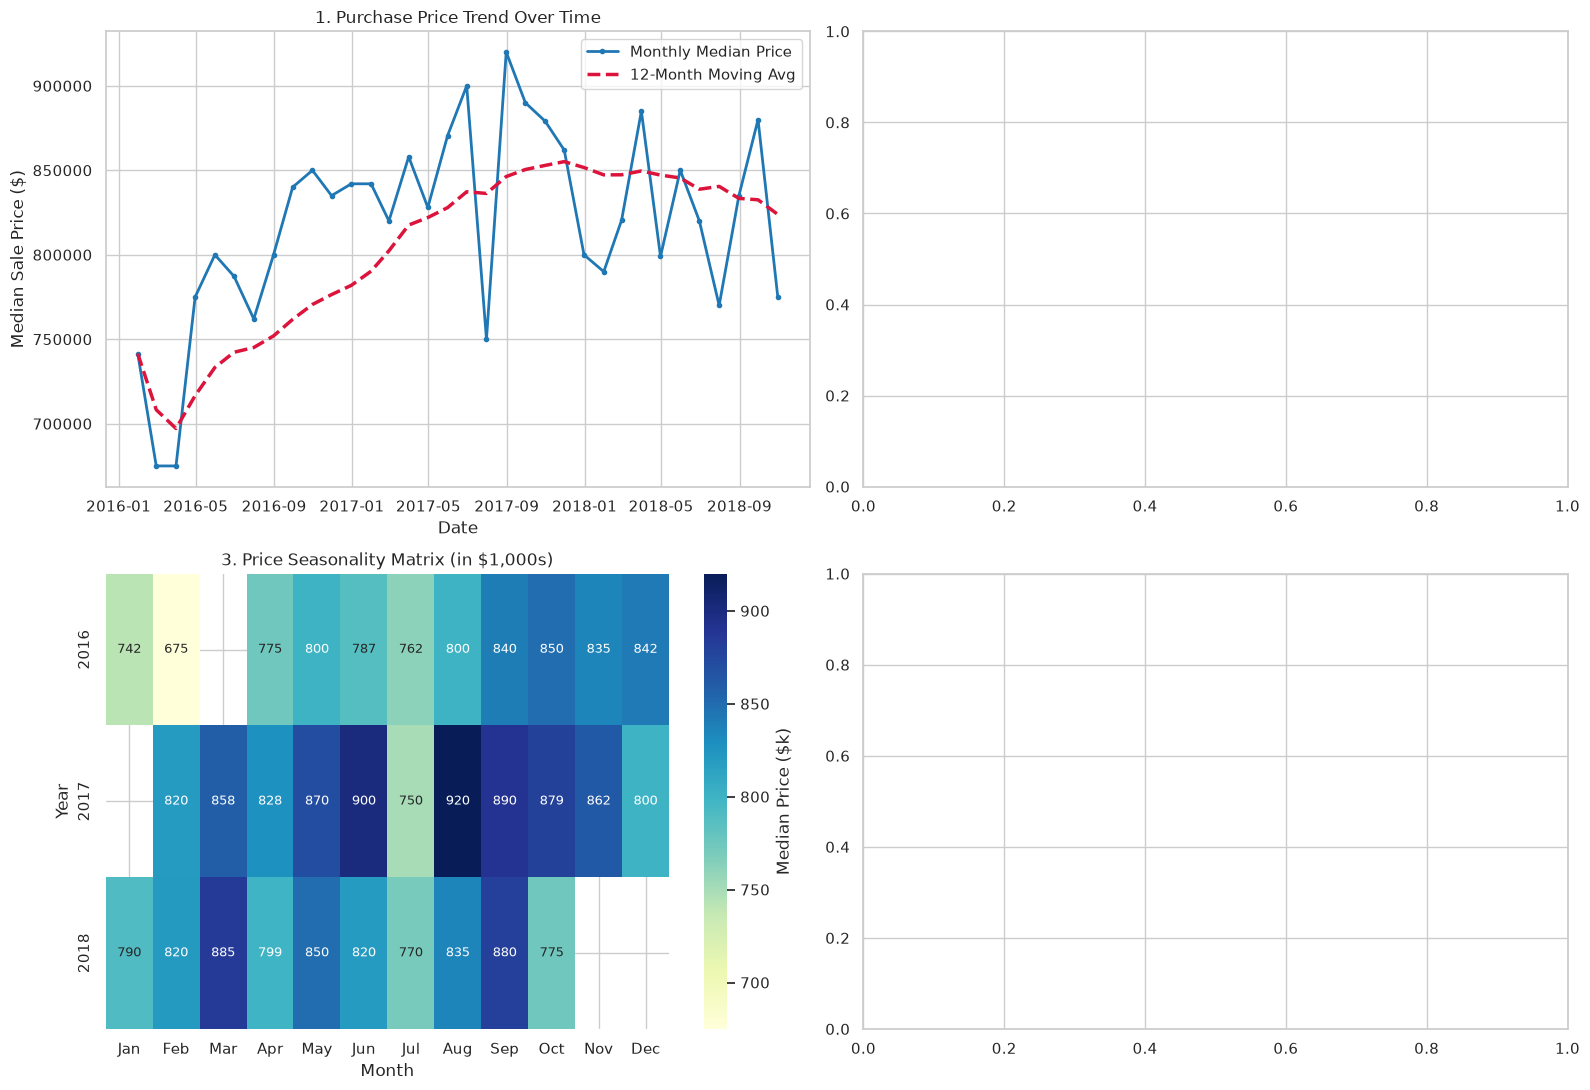


STATIONARITY EVALUATION
=== ADF Test: Raw Monthly Price (d=0) ===
ADF Statistic : -3.5964
p-value       : 0.0058
Status        : ✅ Stationary

=== ADF Test: First-Differenced Price (d=1) ===
ADF Statistic : -6.9894
p-value       : 0.0000
Status        : ✅ Stationary

=== ADF Test: Second-Differenced Price (d=2) ===
ADF Statistic : -5.7281
p-value       : 0.0000
Status        : ✅ Stationary



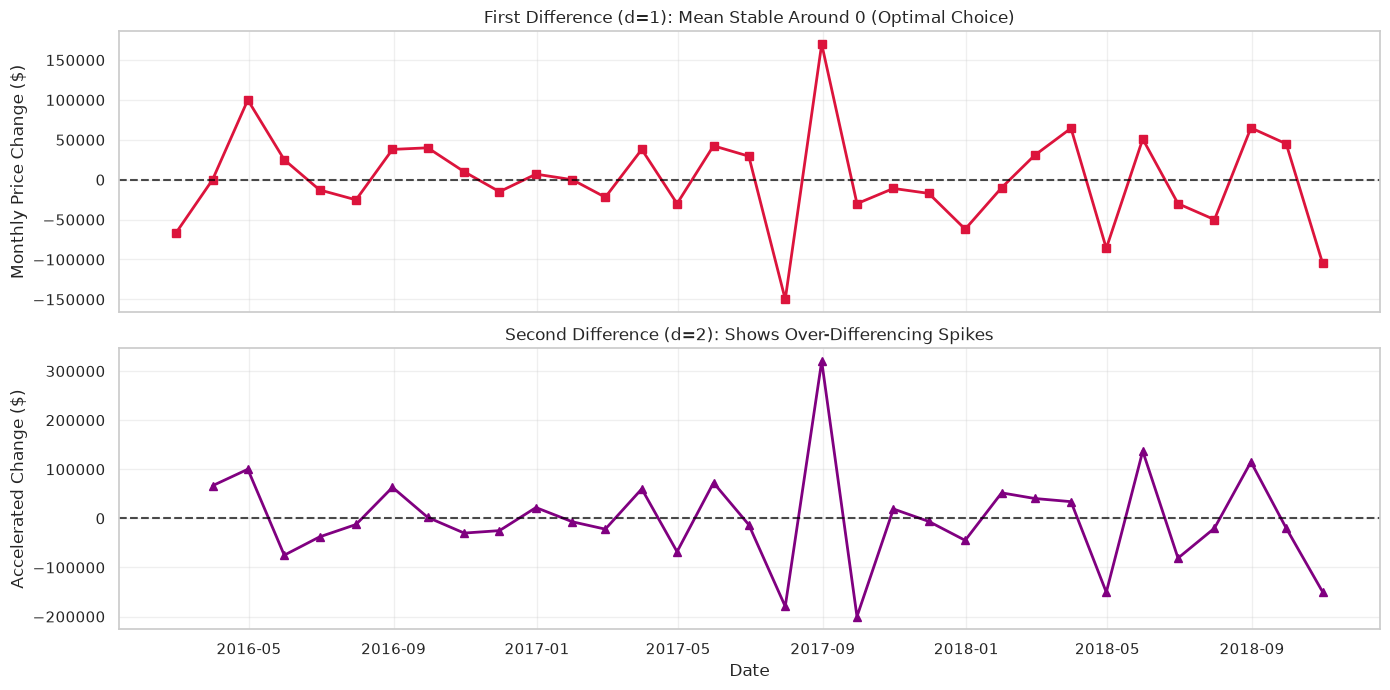


MODEL PERFORMANCE COMPARISON


/home/kwateng/Desktop/Predictive analysis/jupyter_env/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


ARIMA(1,1,1)             | AIC: 822.29 | BIC: 826.78 | In-Sample RMSE: $138,553.64
SARIMA(1,1,1)(1,1,1)12 | AIC: 175.86 | BIC: 175.59 | In-Sample RMSE: $253,900.74

WALK-FORWARD OUT-OF-SAMPLE CROSS-VALIDATION
Test Period: 2018-01 to 2018-03 | ARIMA RMSE: $46,215.78 | SARIMA RMSE: $39,013.06 ✓
Test Period: 2018-03 to 2018-05 | ARIMA RMSE: $45,071.73 | SARIMA RMSE: $31,798.15 ✓
Test Period: 2018-05 to 2018-07 | ARIMA RMSE: $33,074.11 | SARIMA RMSE: $53,258.56 ✓
Test Period: 2018-07 to 2018-09 | ARIMA RMSE: $45,478.15 | SARIMA RMSE: $1,330,697.88 ✓

FINAL OUT-OF-SAMPLE PERFORMANCE SUMMARY
ARIMA(1, 1, 1)             | Mean CV RMSE: $42,459.94
SARIMA(1, 1, 1)(1, 1, 1)12 | Mean CV RMSE: $363,691.91

✅ Winner: ARIMA (Lower out-of-sample forecast variance)


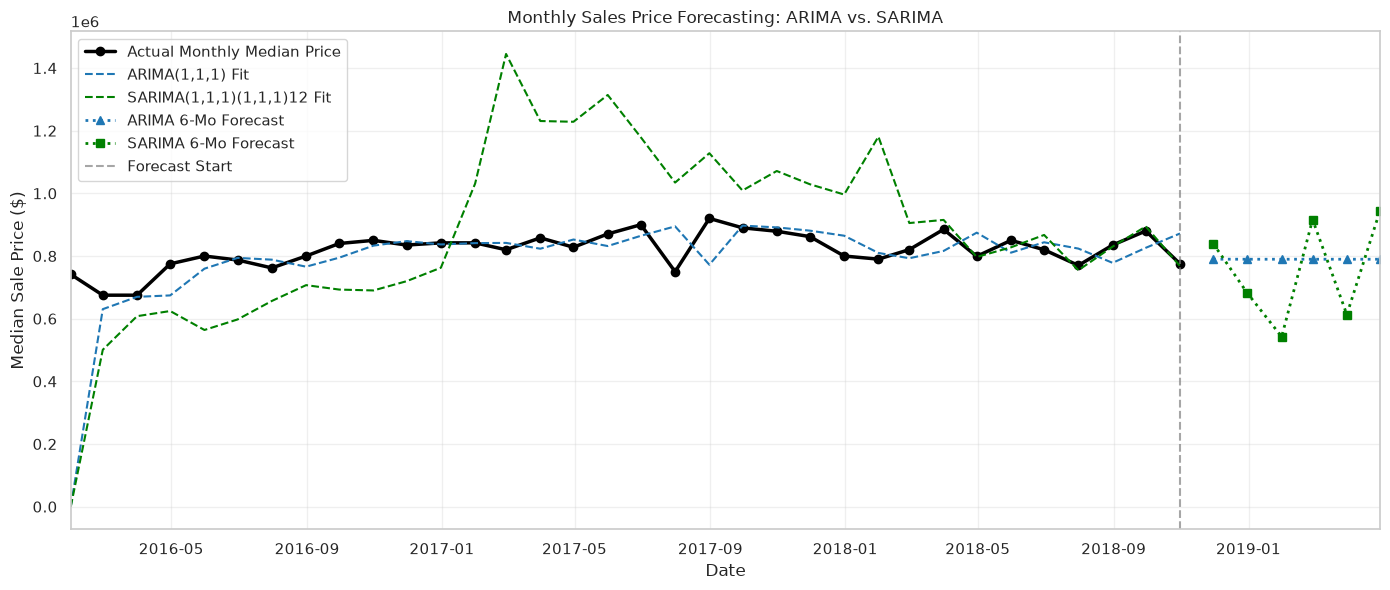


✅ Analysis Complete!
   • Total observations: 34 months
   • ARIMA CV folds: 4
   • SARIMA CV folds: 4


In [40]:
#Necessary import 
import glob #Global path finder
import warnings  #ignore warnings and allow the interpreter behave a complier 
import matplotlib.pyplot as plt # Visualization 
import numpy as np# Mathematical operations
import pandas as pd# handling  structured data set 
import seaborn as sns# Visualizaton 
from sklearn.metrics import mean_squared_error # Sklearn error metrics   the metric used for evalution is the mean_square_error  
from statsmodels.tsa.arima.model import ARIMA # Auto Regression Intergration Moving Average
from statsmodels.tsa.stattools import adfuller # Analyisis tool for handling stationary 
from statsmodels.tsa.statespace.sarimax import SARIMAX #Season Auto regression intergration moving  average 

# Set global visual styles
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.titlesize": 14})

# =====================================================================
# STAGE 1: INGESTION & DATA CLEANING
# =====================================================================
#Loading the dataset into the pipe line 
csv_files = glob.glob("*.csv")
print(f"📦 Ingesting {len(csv_files)} CSV files...")

df_list = []
for file in csv_files:
    try:
        temp_df = pd.read_csv(file)
        temp_df = temp_df.loc[:, ~temp_df.columns.duplicated()]
        temp_df.columns = [c.strip().title() for c in temp_df.columns]

        # Standardize header names

        column_mapping = {
            "Bathroom": "Bathrooms",
            "Bedroom2": "Bedrooms",
            "Council_Area": "Councilarea",
            "Car_Spaces": "Car",
            "Datesold": "Date",
            "Sold_Date": "Date",
            "Listing_Date": "Date",
        }
        temp_df.rename(columns=column_mapping, inplace=True)

        # File classification logic (Sales vs Rental)
        is_rental = "homely" in file.lower() or "Scraped_At" in temp_df.columns
        
        # Alternative rental detection based on price values
        if not is_rental and "Price" in temp_df.columns:
            sample_prices = pd.to_numeric(
                temp_df["Price"].astype(str).str.replace(r'[\$,]', '', regex=True).str.strip(),
                errors='coerce'
            ).dropna()
            if not sample_prices.empty and sample_prices.median() < 3000:
                is_rental = True
        
        if is_rental:
            print(f"  🔑 Detected RENTAL file: {file}")
            if "Price" in temp_df.columns:
                temp_df.rename(columns={"Price": "Rent"}, inplace=True)
            if "Scraped_At" in temp_df.columns and "Date" not in temp_df.columns:
                temp_df["Date"] = temp_df["Scraped_At"]
        else:
            print(f"  🏡 Detected SALES file: {file}")

        temp_df["Source_File"] = file
    # The cleaning sort columns the strip the rental prices  and append  to the list 
        df_list.append(temp_df)
    except Exception as e:
        print(f"   ❌ Skipped {file}: {e}")

if not df_list:
    raise FileNotFoundError("No valid CSV files found in the working directory.")

combined_df = pd.concat(df_list, axis=0, ignore_index=True)
combined_df = combined_df.loc[:, ~combined_df.columns.duplicated()]
#This this where te data is combined vertically 
print(f"\n🔗 Combined Dataset: {combined_df.shape[0]} rows, {combined_df.shape[1]} columns")

# Clean target numeric columns
for col in ["Price", "Rent"]:
    if col in combined_df.columns:
        combined_df[col] = pd.to_numeric(
            combined_df[col].astype(str).str.replace(r"[\$,]", "", regex=True).str.strip(),
            errors="coerce",
        )

# Boundary filtering for outliers
sns.boxplot(combined_df["Price"]) 
plt.show
if "Price" in combined_df.columns:
    combined_df.loc[
        (combined_df["Price"] < 100000) | (combined_df["Price"] > 10000000), "Price"
    ] = np.nan
    print(f"  • Valid Purchase Price rows: {combined_df['Price'].notna().sum()}")

if "Rent" in combined_df.columns:
    combined_df.loc[
        (combined_df["Rent"] < 100) | (combined_df["Rent"] > 5000), "Rent"
    ] = np.nan
    print(f"  • Valid Weekly Rent rows: {combined_df['Rent'].notna().sum()}")

# =====================================================================
# STAGE 2: TIME SERIES RESAMPLING & FREQUENCY SANITATION
# =====================================================================
#Re arranging the data in relation to the how frequent  the day appears
resample_rule = "ME" if pd.__version__ >= "2.2.0" else "M"

if "Date" in combined_df.columns:
    combined_df["Parsed_Date"] = pd.to_datetime(
        combined_df["Date"], format="mixed", dayfirst=True, utc=True, errors="coerce"
    ).dt.tz_localize(None)
#Acummlating the dates and creating a new column called date     
    # Create time series dataframe
    ts_df = combined_df.dropna(subset=["Parsed_Date"]).sort_values("Parsed_Date")
    ts_df['Year'] = ts_df['Parsed_Date'].dt.year
    ts_df['Month_Num'] = ts_df['Parsed_Date'].dt.month
    #sorting the data by data and feature engineering  to a year columns and month_num 

    # Resample and enforce complete continuous temporal frequency
    #filling missing data to ensure the time line is not broken 
    sales_ts = (
        ts_df.dropna(subset=["Price"])
        .resample(resample_rule, on="Parsed_Date")["Price"]
        .median()
        .asfreq(resample_rule)
        .ffill()  # Forward fill missing temporal slots
    )

else:
    raise KeyError("Column 'Date' not found in combined dataset.")

print(f"\n📊 Time Series: {len(sales_ts)} monthly observations from {sales_ts.index[0].strftime('%Y-%m')} to {sales_ts.index[-1].strftime('%Y-%m')}")

# =====================================================================
# STAGE 3: EXPLORATORY VISUALIZATION
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
months_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# 1. Purchase Price Trend
if not sales_ts.empty:
    rolling_price = sales_ts.rolling(window=12, min_periods=1).mean()
    axes[0, 0].plot(sales_ts.index, sales_ts.values, color='#1f77b4', lw=2, marker='o', ms=3, label='Monthly Median Price')
    axes[0, 0].plot(rolling_price.index, rolling_price.values, color='crimson', lw=2.5, linestyle='--', label='12-Month Moving Avg')
    axes[0, 0].set_title('1. Purchase Price Trend Over Time')
    axes[0, 0].set_xlabel('Date')
    axes[0, 0].set_ylabel('Median Sale Price ($)')
    axes[0, 0].legend()

# 2. Rental Price Distribution
if 'Rent' in combined_df.columns and combined_df['Rent'].notna().sum() > 0:
    valid_rents = combined_df['Rent'].dropna()
    rent_dates = ts_df.dropna(subset=['Rent'])['Parsed_Date'].dt.to_period('M')
    
    if rent_dates.nunique() > 1:
        monthly_rent = ts_df.resample(resample_rule, on='Parsed_Date')['Rent'].median().dropna()
        axes[0, 1].plot(monthly_rent.index, monthly_rent.values, color='#2ca02c', lw=2, marker='s')
        axes[0, 1].set_title('2. Rental Price Trend Over Time')
    else:
        sns.histplot(valid_rents, kde=True, ax=axes[0, 1], color='#2ca02c', bins=30)
        median_val = valid_rents.median()
        axes[0, 1].axvline(median_val, color='crimson', linestyle='--', lw=2, label=f'Median Rent: ${median_val:.0f}')
        axes[0, 1].set_title('2. Rental Price Distribution (Snapshot)')
        axes[0, 1].set_xlabel('Weekly Rent ($)')
        axes[0, 1].set_ylabel('Frequency')
        axes[0, 1].legend()

# 3. Price Seasonality Matrix
if not sales_ts.empty:
    pivot_price = ts_df.pivot_table(
        index='Year', columns='Month_Num', values='Price', aggfunc='median'
    ) / 1000
    
    if not pivot_price.empty:
        sns.heatmap(pivot_price, cmap='YlGnBu', annot=True, fmt='.0f', 
                   annot_kws={'size': 9}, ax=axes[1, 0],
                   cbar_kws={'label': 'Median Price ($k)'})
        axes[1, 0].set_title('3. Price Seasonality Matrix (in $1,000s)')
        axes[1, 0].set_xticklabels(months_labels[:pivot_price.shape[1]], rotation=0)
        axes[1, 0].set_xlabel('Month')
        axes[1, 0].set_ylabel('Year')

# 4. Rental Price vs Rooms Breakdown
if 'Rent' in combined_df.columns and 'Rooms' in combined_df.columns:
    rent_room_df = combined_df.dropna(subset=['Rent', 'Rooms']).copy()
    rent_room_df['Rooms'] = rent_room_df['Rooms'].astype(int)
    rent_room_df = rent_room_df[rent_room_df['Rooms'] <= 5]
    
    if not rent_room_df.empty:
        sns.boxplot(data=rent_room_df, x='Rooms', y='Rent', ax=axes[1, 1], 
                   palette='Set2', showfliers=False)
        axes[1, 1].set_title('4. Weekly Rent by Room Count')
        axes[1, 1].set_xlabel('Number of Rooms')
        axes[1, 1].set_ylabel('Weekly Rent ($)')

plt.tight_layout()
plt.show()

# =====================================================================
# STAGE 4: ECONOMETRIC STATIONARITY TESTING (ADF)
# =====================================================================
def run_adf_test(series, name):
    """Run Augmented Dickey-Fuller test for stationarity"""
    res = adfuller(series.dropna())
    print(f"=== ADF Test: {name} ===")
    print(f"ADF Statistic : {res[0]:.4f}")
    print(f"p-value       : {res[1]:.4f}")
    print(f"Status        : {'✅ Stationary' if res[1] < 0.05 else '❌ Non-Stationary (Differencing Required)'}\n")
    return res[1] < 0.05

#checking for stationary  first level 

print("\n" + "="*50)
print("STATIONARITY EVALUATION")
print("="*50)

is_stationary = run_adf_test(sales_ts, "Raw Monthly Price (d=0)")
sales_diff1 = sales_ts.diff().dropna()
run_adf_test(sales_diff1, "First-Differenced Price (d=1)")
sales_diff2 = sales_diff1.diff().dropna()
run_adf_test(sales_diff2, "Second-Differenced Price (d=2)")

# Plot differencing comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(sales_diff1.index, sales_diff1.values, color='crimson', lw=2, marker='s')
axes[0].axhline(0, color='black', linestyle='--', alpha=0.7)
axes[0].set_title('First Difference (d=1): Mean Stable Around 0 (Optimal Choice)')
axes[0].set_ylabel('Monthly Price Change ($)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(sales_diff2.index, sales_diff2.values, color='purple', lw=2, marker='^')
axes[1].axhline(0, color='black', linestyle='--', alpha=0.7)
axes[1].set_title('Second Difference (d=2): Shows Over-Differencing Spikes')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Accelerated Change ($)')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================================
# STAGE 5: MODEL FITTING & COMPARISON
# =====================================================================
print("\n" + "="*50)
print("MODEL PERFORMANCE COMPARISON")
print("="*50)

# Fit models on full dataset
arima_full = ARIMA(sales_ts, order=(1, 1, 1)).fit()
sarima_full = SARIMAX(
    sales_ts,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

# Generate in-sample predictions
arima_pred = arima_full.fittedvalues
sarima_pred = sarima_full.fittedvalues

# Calculate in-sample RMSE
arima_eval = pd.DataFrame({'actual': sales_ts, 'pred': arima_pred}).dropna()
sarima_eval = pd.DataFrame({'actual': sales_ts, 'pred': sarima_pred}).dropna()

arima_rmse_insample = np.sqrt(mean_squared_error(arima_eval['actual'], arima_eval['pred']))
sarima_rmse_insample = np.sqrt(mean_squared_error(sarima_eval['actual'], sarima_eval['pred']))

print(f"ARIMA(1,1,1)             | AIC: {arima_full.aic:.2f} | BIC: {arima_full.bic:.2f} | In-Sample RMSE: ${arima_rmse_insample:,.2f}")
print(f"SARIMA(1,1,1)(1,1,1)12 | AIC: {sarima_full.aic:.2f} | BIC: {sarima_full.bic:.2f} | In-Sample RMSE: ${sarima_rmse_insample:,.2f}")

# =====================================================================
# STAGE 6: WALK-FORWARD CROSS-VALIDATION
# =====================================================================
min_train_size = 24  # Require minimum 24 months for seasonal convergence
horizon = 3          # 3-month forecast horizon
step = 2             # Expanding step

arima_cv_errors = []
sarima_cv_errors = []
fold_info = []

print("\n" + "="*50)
print("WALK-FORWARD OUT-OF-SAMPLE CROSS-VALIDATION")
print("="*50)

for start_idx in range(min_train_size, len(sales_ts) - horizon + 1, step):
    train_data = sales_ts.iloc[:start_idx]
    test_data = sales_ts.iloc[start_idx : start_idx + horizon]
    
    # Skip if training data is too short for seasonal model
    if len(train_data) < 24:
        continue

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        
        # Fit ARIMA(1, 1, 1)
        model_arima = ARIMA(train_data, order=(1, 1, 1)).fit()
        pred_arima = model_arima.forecast(steps=horizon)

        # Fit SARIMA(1, 1, 1)(1, 1, 1)_12
        try:
            model_sarima = SARIMAX(
                train_data,
                order=(1, 1, 1),
                seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False,
            ).fit(disp=False)
            pred_sarima = model_sarima.forecast(steps=horizon)
            sarima_valid = True
        except:
            sarima_valid = False
            pred_sarima = np.full(horizon, np.nan)

    rmse_a = np.sqrt(mean_squared_error(test_data, pred_arima))
    arima_cv_errors.append(rmse_a)
    
    if sarima_valid:
        rmse_s = np.sqrt(mean_squared_error(test_data, pred_sarima))
        sarima_cv_errors.append(rmse_s)
        sarima_valid_flag = "✓"
    else:
        rmse_s = np.nan
        sarima_valid_flag = "✗"
    
    fold_info.append({
        'train_end': train_data.index[-1].strftime('%Y-%m'),
        'test_start': test_data.index[0].strftime('%Y-%m'),
        'test_end': test_data.index[-1].strftime('%Y-%m'),
        'arima_rmse': rmse_a,
        'sarima_rmse': rmse_s,
        'sarima_valid': sarima_valid_flag
    })

# Print fold results
for fold in fold_info:
    print(f"Test Period: {fold['test_start']} to {fold['test_end']} | "
          f"ARIMA RMSE: ${fold['arima_rmse']:,.2f} | "
          f"SARIMA RMSE: ${fold['sarima_rmse']:,.2f} {fold['sarima_valid']}")

# Calculate mean errors
mean_arima_rmse = np.mean(arima_cv_errors)
mean_sarima_rmse = np.mean(sarima_cv_errors) if sarima_cv_errors else np.nan

print("\n" + "="*50)
print("FINAL OUT-OF-SAMPLE PERFORMANCE SUMMARY")
print("="*50)
print(f"ARIMA(1, 1, 1)             | Mean CV RMSE: ${mean_arima_rmse:,.2f}")
print(f"SARIMA(1, 1, 1)(1, 1, 1)12 | Mean CV RMSE: ${mean_sarima_rmse:,.2f}")

if mean_sarima_rmse < mean_arima_rmse:
    print("\n✅ Winner: SARIMA (Seasonal component improves multi-step accuracy)")
else:
    print("\n✅ Winner: ARIMA (Lower out-of-sample forecast variance)")

# =====================================================================
# STAGE 7: FORECAST VISUALIZATION
# =====================================================================
forecast_steps = 6

# Generate forecasts
arima_forecast = arima_full.forecast(steps=forecast_steps)
sarima_forecast = sarima_full.forecast(steps=forecast_steps)

# Plot comparison
plt.figure(figsize=(14, 6))

# Actual values
plt.plot(sales_ts.index, sales_ts.values, label='Actual Monthly Median Price', 
         color='black', lw=2.5, marker='o')

# Fitted values
plt.plot(arima_eval.index, arima_eval['pred'], label='ARIMA(1,1,1) Fit', 
         color='#1f77b4', linestyle='--')
plt.plot(sarima_eval.index, sarima_eval['pred'], label='SARIMA(1,1,1)(1,1,1)12 Fit', 
         color='green', linestyle='--')

# Out-of-sample Forecast
plt.plot(arima_forecast.index, arima_forecast.values, label='ARIMA 6-Mo Forecast', 
         color='#1f77b4', lw=2, marker='^', linestyle=':')
plt.plot(sarima_forecast.index, sarima_forecast.values, label='SARIMA 6-Mo Forecast', 
         color='green', lw=2, marker='s', linestyle=':')

plt.axvline(x=sales_ts.index[-1], color='gray', linestyle='--', alpha=0.7, label='Forecast Start')
plt.title('Monthly Sales Price Forecasting: ARIMA vs. SARIMA')
plt.xlabel('Date')
plt.ylabel('Median Sale Price ($)')
plt.xlim([sales_ts.index[0], arima_forecast.index[-1]])
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n✅ Analysis Complete!")
print(f"   • Total observations: {len(sales_ts)} months")
print(f"   • ARIMA CV folds: {len(arima_cv_errors)}")
print(f"   • SARIMA CV folds: {len(sarima_cv_errors)}")

## Regression Analysis

📦 Pipeline Ingestion: Found 4 CSV datasets in folder.
/n======Inspecting the Combined data set=======          Suburb           Address  Rooms Type      Price Method   Sellerg  \
0    Abbotsford     49 Lithgow St    3.0    h  1490000.0      S    Jellis   
1    Abbotsford     59A Turner St    3.0    h  1220000.0      S  Marshall   
2    Abbotsford     119B Yarra St    3.0    h  1420000.0      S    Nelson   
3    Aberfeldie        68 Vida St    3.0    h  1515000.0      S     Barry   
4  Airport West  92 Clydesdale Rd    2.0    h   670000.0      S    Nelson   

        Date  Postcode             Regionname  ...  Price (New)  Change (New)  \
0  1/04/2017    3067.0  Northern Metropolitan  ...          NaN           NaN   
1  1/04/2017    3067.0  Northern Metropolitan  ...          NaN           NaN   
2  1/04/2017    3067.0  Northern Metropolitan  ...          NaN           NaN   
3  1/04/2017    3040.0   Western Metropolitan  ...          NaN           NaN   
4  1/04/2017    3042.0   Weste

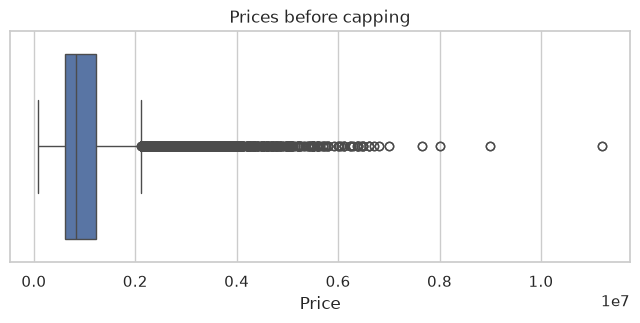

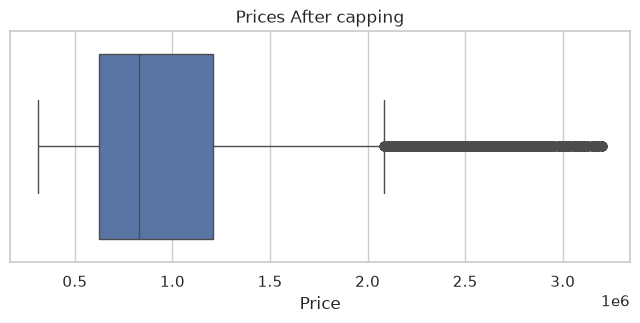

         Suburb           Address  Rooms Type      Price Method   Sellerg  \
0    Abbotsford     49 Lithgow St    3.0    h  1490000.0      S    Jellis   
1    Abbotsford     59A Turner St    3.0    h  1220000.0      S  Marshall   
2    Abbotsford     119B Yarra St    3.0    h  1420000.0      S    Nelson   
3    Aberfeldie        68 Vida St    3.0    h  1515000.0      S     Barry   
4  Airport West  92 Clydesdale Rd    2.0    h   670000.0      S    Nelson   

        Date  Postcode             Regionname  ...  Price (Modern)  \
0  1/04/2017    3067.0  Northern Metropolitan  ...             NaN   
1  1/04/2017    3067.0  Northern Metropolitan  ...             NaN   
2  1/04/2017    3067.0  Northern Metropolitan  ...             NaN   
3  1/04/2017    3040.0   Western Metropolitan  ...             NaN   
4  1/04/2017    3042.0   Western Metropolitan  ...             NaN   

   Change (Modern) Price (Older)  Change (Older)  Suburb_Source  State  \
0              NaN           NaN          

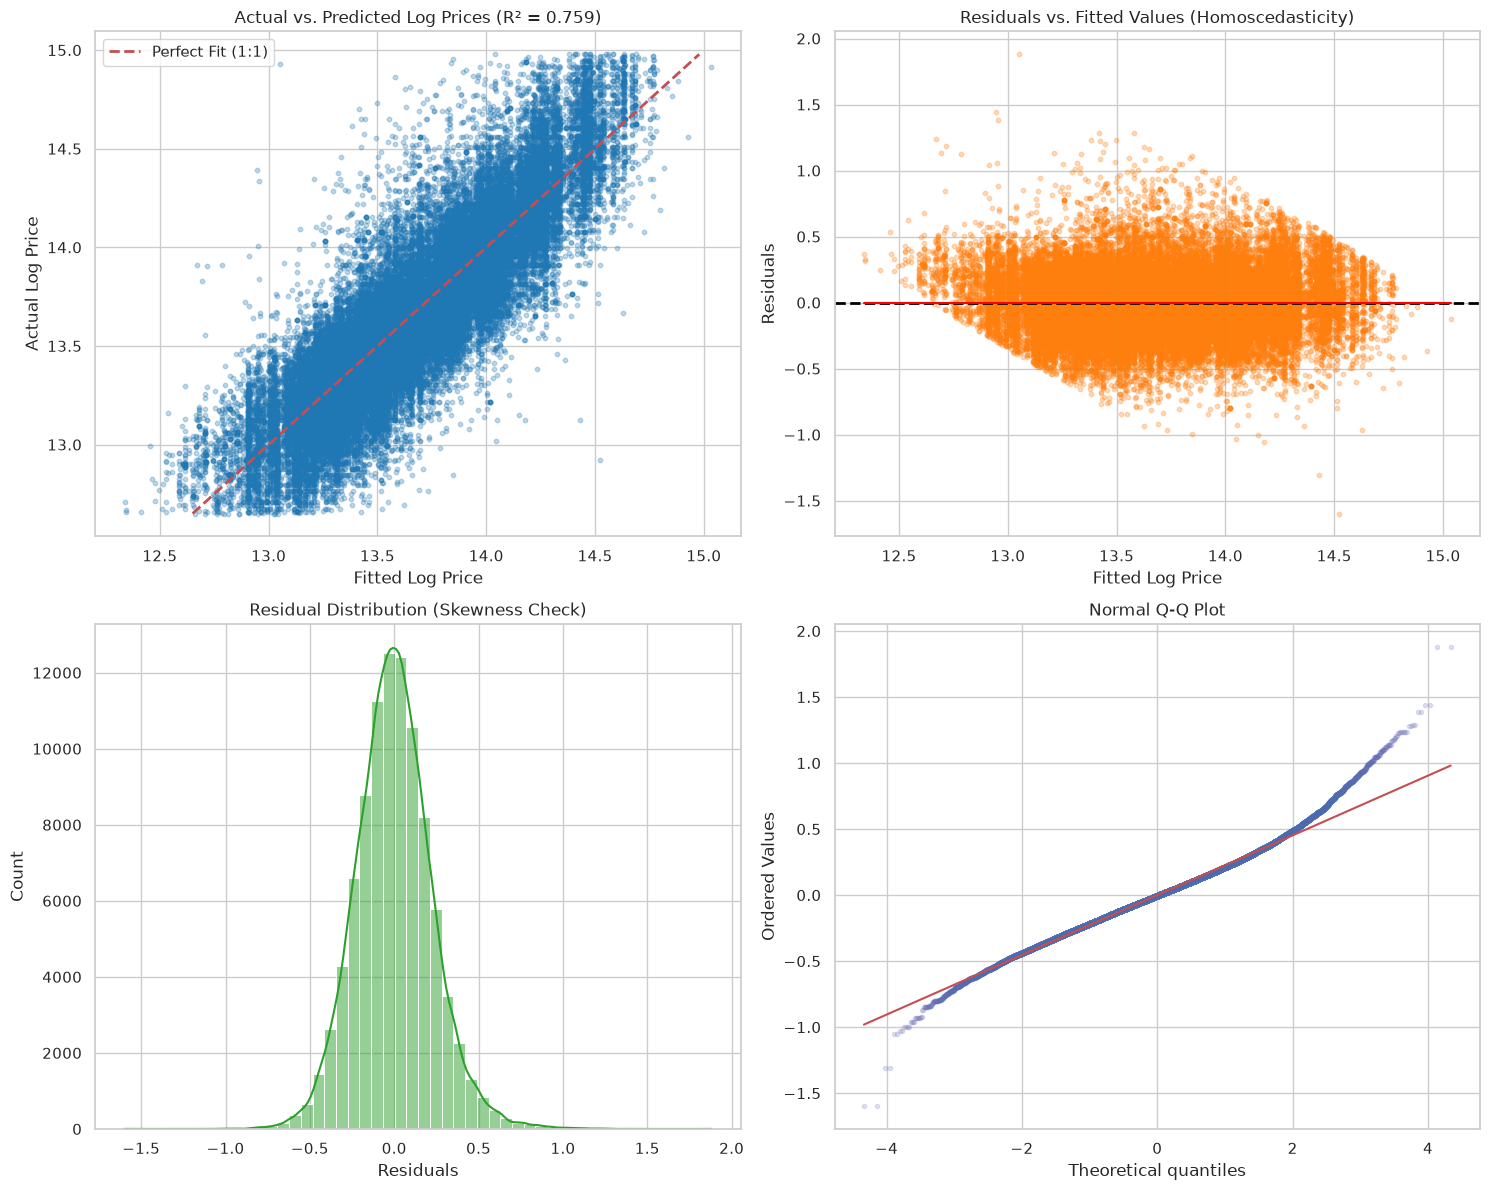

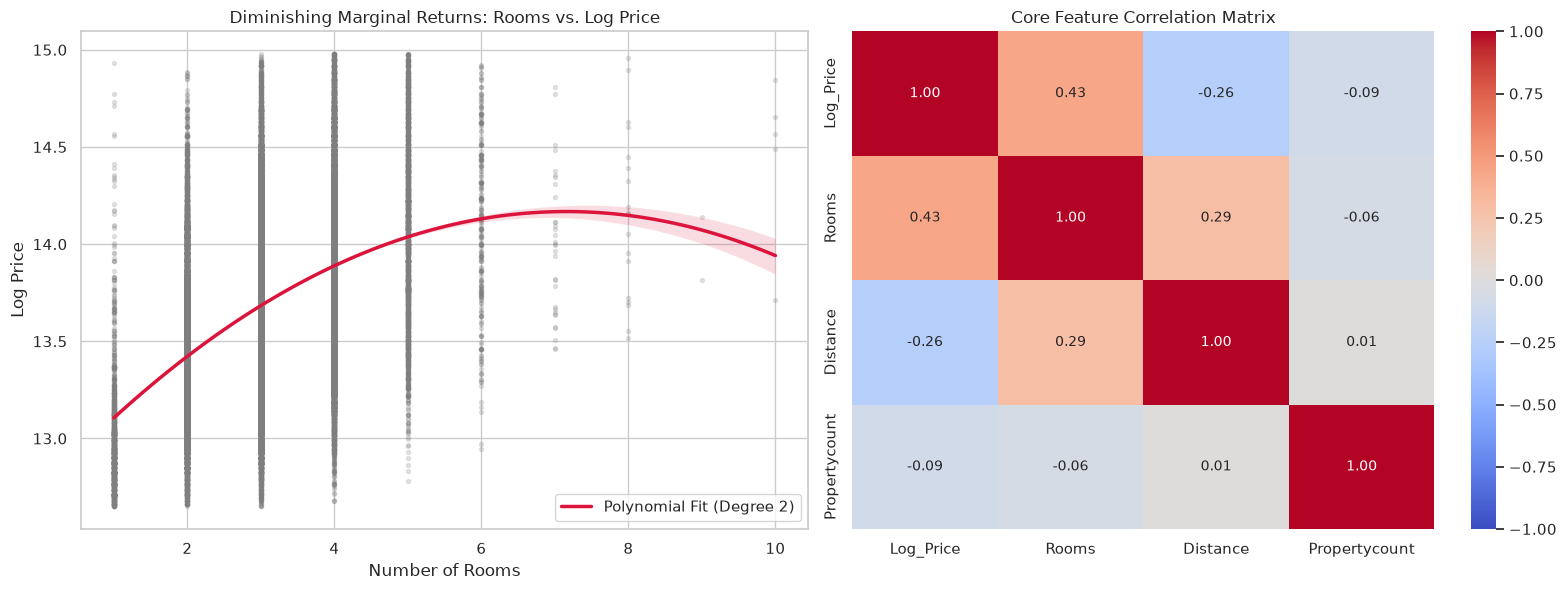

In [21]:
# Importing necessary Libraries and Packages
import glob  # Finding path patterns
import matplotlib.pyplot as plt  # Visualization tool
import numpy as np  # Mathematical calculations
import pandas as pd  # Structured dataframe manipulation
import scipy.stats as stats  # Statistical functions and p-values
import seaborn as sns  # Advanced statistical visualizations
import statsmodels.api as sm  # Statsmodels OLS modeling

from sklearn.impute import SimpleImputer  # Missing value imputation
from sklearn.linear_model import Lasso, LassoCV, Ridge, RidgeCV  # Regularized Linear Models
from sklearn.metrics import mean_squared_error, r2_score  # Regression evaluation metrics
from sklearn.model_selection import train_test_split  # Train/Test split split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler  # Preprocessing

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.titlesize": 14})

# =====================================================================
# STAGE 1: INGESTION & AUTOMATIC COLUMN EXPANSION
# =====================================================================
csv_files = glob.glob("*.csv")  # Find matching CSV files in current folder
print(f"📦 Pipeline Ingestion: Found {len(csv_files)} CSV datasets in folder.")
#Feeding the csv file in to  pipe for the first preprocessing 
#selecting the unqiue columns as topic headers
df_list = []
for file in csv_files:
    try:
        temp_df = pd.read_csv(file)
        temp_df = temp_df.loc[:, ~temp_df.columns.duplicated()]
        temp_df.columns = [c.strip().title() for c in temp_df.columns]
        df_list.append(temp_df)
    except Exception as e:
        print(f"   ❌ Skipped {file}: {e}")
# Concatenate datasets vertically
combined_df = pd.concat(df_list, axis=0, ignore_index=True)
combined_df = combined_df.loc[:, ~combined_df.columns.duplicated()]
print ("/n======Inspecting the Combined data set=======",combined_df.head())
# =====================================================================
# STAGE 2: SANITIZATION, RENTAL FILTERING & DOMAIN FEATURE CREATION
# =====================================================================
# Standardize header variations across merged CSV s
column_mapping = {
    "Bathroom": "Bathrooms",
    "Bedroom2": "Bedrooms",
    "Car_Spaces": "Car",
    "Car Spaces": "Car",
    "Council_Area": "Councilarea",
}
combined_df.rename(columns=column_mapping, inplace=True)

# Guard against duplicate columns created via mapping
combined_df = combined_df.loc[:, ~combined_df.columns.duplicated()]

if "Price" in combined_df.columns:
    combined_df["Price"] = (
        combined_df["Price"]
        .astype(str)
        .str.replace(r"[\$,]", "", regex=True)
        .str.strip()
    )
    combined_df["Price"] = pd.to_numeric(combined_df["Price"], errors="coerce")

# 1. Drop missing target values
combined_df = combined_df.dropna(subset=["Price"]).reset_index(drop=True)

# Plotting box plot to view raw outliers
plt.figure(figsize=(8, 3))
sns.boxplot(x=combined_df["Price"])
plt.title("Prices before capping")
plt.show()

# 3. Trim extreme price outliers (1% - 99%)
#I a qaintile range of 1 percent and 99 % ensures a majority of the price are included  in the model's analyisis 
q_low = combined_df["Price"].quantile(0.01)
q_high = combined_df["Price"].quantile(0.99)
combined_df = combined_df[
    (combined_df["Price"] >= q_low) & (combined_df["Price"] <= q_high)
].reset_index(drop=True)

# Plotting box plot to view capped distribution
plt.figure(figsize=(8, 3))
sns.boxplot(x=combined_df["Price"])
plt.title("Prices After capping")
plt.show()

# 4. Invalidate shifted postcodes & bad values in structural columns
for col in ["Bathrooms", "Bedrooms", "Car", "Rooms"]:
    if col in combined_df.columns:
        combined_df[col] = pd.to_numeric(combined_df[col], errors="coerce")
        # Replace counts outside 1..10 with NaN for median imputation
        combined_df.loc[(combined_df[col] < 1) | (combined_df[col] > 10), col] = np.nan

# Filter out uninformative rows where Rooms is unassigned
if "Rooms" in combined_df.columns:
    combined_df = combined_df[combined_df["Rooms"].notna()].reset_index(drop=True)

# 5. DOMAIN FEATURE: Intuitive Commuter Location Tiers
if "Distance" in combined_df.columns:
    combined_df["Distance"] = pd.to_numeric(combined_df["Distance"], errors="coerce")
    combined_df["Location_Tier"] = pd.cut(
        combined_df["Distance"],
        bins=[-1, 5, 15, np.inf],
        labels=["Inner_City", "Middle_Suburbs", "Outer_Suburbs"],
    )

combined_df["Log_Price"] = np.log(combined_df["Price"])
print(combined_df.head())
print(f"🧹 Cleaned Sales Dataset Ready: {len(combined_df)} valid property sales rows.")

# =====================================================================
# STAGE 3: EXPANDED NUMERIC IMPUTATION & POLYNOMIAL EXPANSION
# =====================================================================
#Fearture selections 
physical_cols = [
    "Rooms",
    "Distance",
    "Bathrooms",
    "Bedrooms",
    "Car",
    "Landsize",
    "Buildingarea",
    "Propertycount",
]
num_features = [c for c in physical_cols if c in combined_df.columns]

X_raw = combined_df[num_features].copy()

# Convert features to numeric and handle zero entries for structural metrics

for col in X_raw.columns:
    X_raw[col] = pd.to_numeric(X_raw[col], errors="coerce")
    if col in ["Rooms",
    "Distance",
    "Bathrooms",
    "Bedrooms",
    "Car",
    "Landsize",
    "Buildingarea",
    "Propertycount"]:
        X_raw[col] = X_raw[col].replace(0, np.nan)

# Drop features that are entirely NaN across all datasets
X_raw = X_raw.dropna(how="all", axis=1)
active_features = list(X_raw.columns)
#Checking for missing values 
print("The missing values are as follow:", X_raw.isnull().sum())
# 1. Median Imputation for missing values
imputer = SimpleImputer(strategy="median")
X_imputed_array = imputer.fit_transform(X_raw)
X_imputed_df = pd.DataFrame(
    X_imputed_array, columns=active_features, index=combined_df.index
)
print("Confirming the missing values ",X_raw.isnull().sum())
# 2. Mean-Centering prior to degree-2 polynomial expansion
#Introducing the cuvres to the model using the polynomial expanision 
X_centered = X_imputed_df - X_imputed_df.mean() #X_center is how far the values deviate from the mean 

# 3. Degree-2 Polynomial Expansion
poly = PolynomialFeatures(degree=2, include_bias=False) # calling the polynomialfeature in the memory 
X_poly_array = poly.fit_transform(X_centered)
X_poly_df = pd.DataFrame(
    X_poly_array,
    columns=poly.get_feature_names_out(active_features),
    index=combined_df.index,
)
print("Confirming the X_poly_df, "  , X_poly_df.head())
# =====================================================================
# STAGE 4: CATEGORICAL ENCODING & SUBURB BALANCING
# =====================================================================
cat_dfs = [X_poly_df]
#Introducing categorical features to model  through one hot endcoding 
if "Location_Tier" in combined_df.columns:
    location_dummies = pd.get_dummies(
        combined_df["Location_Tier"], prefix="Loc", drop_first=True, dtype=int
    )
    cat_dfs.append(location_dummies)

if "Type" in combined_df.columns:
    type_dummies = pd.get_dummies(
        combined_df["Type"], prefix="Type", drop_first=True, dtype=int
    )
    cat_dfs.append(type_dummies)

if "Suburb" in combined_df.columns:
    suburb_counts = combined_df["Suburb"].value_counts()
    top_suburbs = suburb_counts[suburb_counts >= 100].index

    combined_df["Suburb_Grouped"] = combined_df["Suburb"].where(
        combined_df["Suburb"].isin(top_suburbs), "Other"
    )
    suburb_dummies = pd.get_dummies(
        combined_df["Suburb_Grouped"], prefix="Sub", drop_first=True, dtype=int
    )
    cat_dfs.append(suburb_dummies)
    print(f"📍 Micro-Location Added: Encoded {len(top_suburbs)} high-frequency suburbs.") #THe number of  sub areas encoded 
elif "Regionname" in combined_df.columns:
    region_dummies = pd.get_dummies(
        combined_df["Regionname"], prefix="Region", drop_first=True, dtype=int
    )#if we cant find the sub area use the region name 
    cat_dfs.append(region_dummies)

X_full = pd.concat(cat_dfs, axis=1) #add the categorical dummy set to the orginal dataframe 

# Standard Scaling
scaler = StandardScaler() # Applying the standard scaler so the model can have a better view 
X_scaled = pd.DataFrame(scaler.fit_transform(X_full), columns=X_full.columns) # final x values features  
y = combined_df["Log_Price"]# Final target

# =====================================================================
# STAGE 5 & 6: DRAFT OLS & P-VALUE FEATURE PRUNING
# =====================================================================
print("\n📐 Fitting Draft OLS Model...")
#Applying the Ordinary least Sqaure to Identify the singificant values of the feautes how important the feautures to the model 
X_sm = sm.add_constant(X_scaled)
draft_model = sm.OLS(y, X_sm).fit()
#Indentifying our significant value
alpha = 0.05
#Storing our p values for the final feature selection 
p_values = draft_model.pvalues
significant_cols = p_values[p_values < alpha].index.tolist()
#The feauture selection using the significant values 
if "const" not in significant_cols:
    significant_cols.append("const")

dropped_count = len(X_sm.columns) - len(significant_cols)
print(f"✂️ Pruned {dropped_count} insignificant features (p >= {alpha})...")

X_sm_pruned = X_sm[significant_cols]
#Displaying the final columns selected 
print("final columns ," ,X_sm_pruned.columns
final_model = sm.OLS(y, X_sm_pruned).fit()

print("\n🏆 Final Pruned OLS Summary:")
print(final_model.summary())

# =====================================================================
# STAGE 7 & 8: L1 (LASSO) & L2 (RIDGE) REGULARIZATION
# =====================================================================

X_reg = X_sm_pruned.drop(columns=["const"], errors="ignore") 
y_reg = y.copy()
#Splitng the data in training and testing sets 80% for training and 20% for testing and even though we are picking at random but at the start pick from index 42
X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Ridge CV (L2)
alphas_ridge = np.logspace(-3, 3, 100) #This create a range of alphas for the model to search through  create a 100 alphas between 10^-3 to 10^3
ridge = RidgeCV(alphas=alphas_ridge, cv=5) # This is a ridge regression L2 with a cross validation analysis  what its means is create a cross validation dummy , 4 for training and 1 for testing  the provide average alpha as the ultimate alpha
ridge.fit(X_train, y_train) #Training the model

# Lasso CV (L1)
alphas_lasso = np.logspace(-5, 1, 100)
lasso = LassoCV(
    alphas=alphas_lasso, cv=5, max_iter=10000, random_state=42
)# The same logic for l1 create multiple alphas between 10"-5 and 10
lasso.fit(X_train, y_train)

print("\n" + "=" * 65)
print("             REGULARIZATION PERFORMANCE COMPARISON              ")
print("=" * 65)
print(f"🔹 L2 (Ridge) Optimal Alpha (λ) : {ridge.alpha_:.4f}")
print(f"   - Test R²                     : {r2_score(y_test, ridge.predict(X_test)):.4f}")
print("-" * 65)
print(f"🔸 L1 (Lasso) Optimal Alpha (λ) : {lasso.alpha_:.6f}")
print(f"   - Test R²                     : {r2_score(y_test, lasso.predict(X_test)):.4f}")
print(f"   - Zeroed Out Features         : {np.sum(lasso.coef_ == 0)} of {X_reg.shape[1]}")
print("=" * 65)

# =====================================================================
# STAGE 9 & 10: EDA VISUALIZATIONS & DIAGNOSTICS
# =====================================================================
y_pred = final_model.fittedvalues
residuals = final_model.resid

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Actual vs Predicted
axes[0, 0].scatter(y_pred, y, alpha=0.15, color="#1f77b4", s=10)
axes[0, 0].plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    "r--",
    lw=2,
    label="Perfect Fit (1:1)",
)
axes[0, 0].set_title(
    f"Actual vs. Predicted Log Prices (R² = {final_model.rsquared:.3f})"
)
axes[0, 0].set_xlabel("Fitted Log Price")
axes[0, 0].set_ylabel("Actual Log Price")
axes[0, 0].legend()

# 2. Residuals vs Fitted
axes[0, 1].scatter(y_pred, residuals, alpha=0.15, color="#ff7f0e", s=10)
axes[0, 1].axhline(0, color="black", linestyle="--", lw=2)
sns.regplot(
    x=y_pred,
    y=residuals,
    ax=axes[0, 1],
    scatter=False,
    color="red",
    line_kws={"lw": 1.5},
)
axes[0, 1].set_title("Residuals vs. Fitted Values (Homoscedasticity)")
axes[0, 1].set_xlabel("Fitted Log Price")
axes[0, 1].set_ylabel("Residuals")

# 3. Residual Distribution
sns.histplot(residuals, kde=True, ax=axes[1, 0], color="#2ca02c", bins=50)
axes[1, 0].set_title("Residual Distribution (Skewness Check)")
axes[1, 0].set_xlabel("Residuals")

# 4. Normal Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_markerfacecolor("#9467bd")
axes[1, 1].get_lines()[0].set_markersize(3.0)
axes[1, 1].get_lines()[0].set_alpha(0.2)
axes[1, 1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

# Polynomial Quadratic Curvature & Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.regplot(
    x="Rooms",
    y="Log_Price",
    data=combined_df,
    order=2,
    ax=axes[0],
    scatter_kws={"alpha": 0.1, "color": "#7f7f7f", "s": 8},
    line_kws={
        "color": "crimson",
        "linewidth": 2.5,
        "label": "Polynomial Fit (Degree 2)",
    },
)
axes[0].set_title("Diminishing Marginal Returns: Rooms vs. Log Price")
axes[0].set_xlabel("Number of Rooms")
axes[0].set_ylabel("Log Price")
axes[0].legend()

core_features = [
    "Log_Price",
    "Rooms",
    "Distance",
    "Bathrooms",
    "Bedrooms",
    "Propertycount",
]
existing_core = [c for c in core_features if c in combined_df.columns]
sns.heatmap(
    combined_df[existing_core].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[1],
    vmin=-1,
    vmax=1,
)
axes[1].set_title("Core Feature Correlation Matrix")

plt.tight_layout()
plt.show()